In [1]:
from pathlib import Path

%cd ../..

d:\User Installed Folders\Master Thesis


In [2]:
from stable_baselines3 import SAC

from Simulation.Auxilaries.io import load_env_ship
from Simulation.Auxilaries.sim_config import sim_config
from Agent.Observation.observation import build_observation
from Explanations.Lime.lime import LimeExplainer
from Explanations.Lime.lime_model import RunValueClass, Source
from Explanations.Lime.peragentcontroller import PerAgentController, IslandPerturbation

example_path = Path("Scenarios/Positional/base.json")
model_path = Path("sac_ship_07_0_1.6m.zip")

model = SAC.load(model_path)

env, ship = load_env_ship(example_path, sim_config)
#Manually extracted by launching Controller.Main and loading the env
point_on_island = (0,-950)

pac = PerAgentController(sim_config, model)
pac.new_training_instance(pre_made_env=env, pre_made_ship=ship)
state = build_observation(pac, reduced=True)["state"]

7


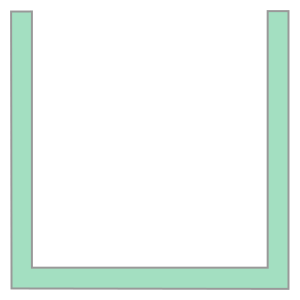

In [3]:
island_id = pac.get_island_id_at(point_on_island)
print(island_id)
island = pac.get_island(island_id)
island

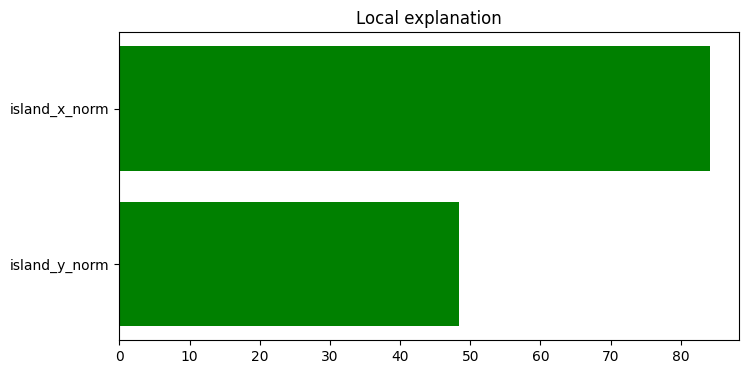

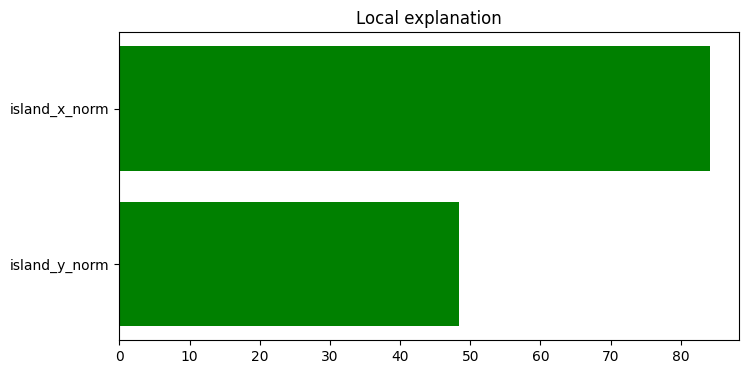

In [4]:
lime = LimeExplainer(pac)

stepcount_explanation = lime.get_explainer_instance(
    state,
    RunValueClass.STEPCOUNT,
    num_samples=1000,
    island_mode=True,
    island_id=island_id
)

stepcount_explanation.as_pyplot_figure(figsize=(8, 4))

In [5]:
island_grid_field = lime.evaluate_island_grid(
    explanation=stepcount_explanation,
    target=RunValueClass.STEPCOUNT,
    island_id=island_id,
    size_x=400.0,
    size_y=400.0,
    num_x=20,
    num_y=20,
    discretize_continuous=False,
)

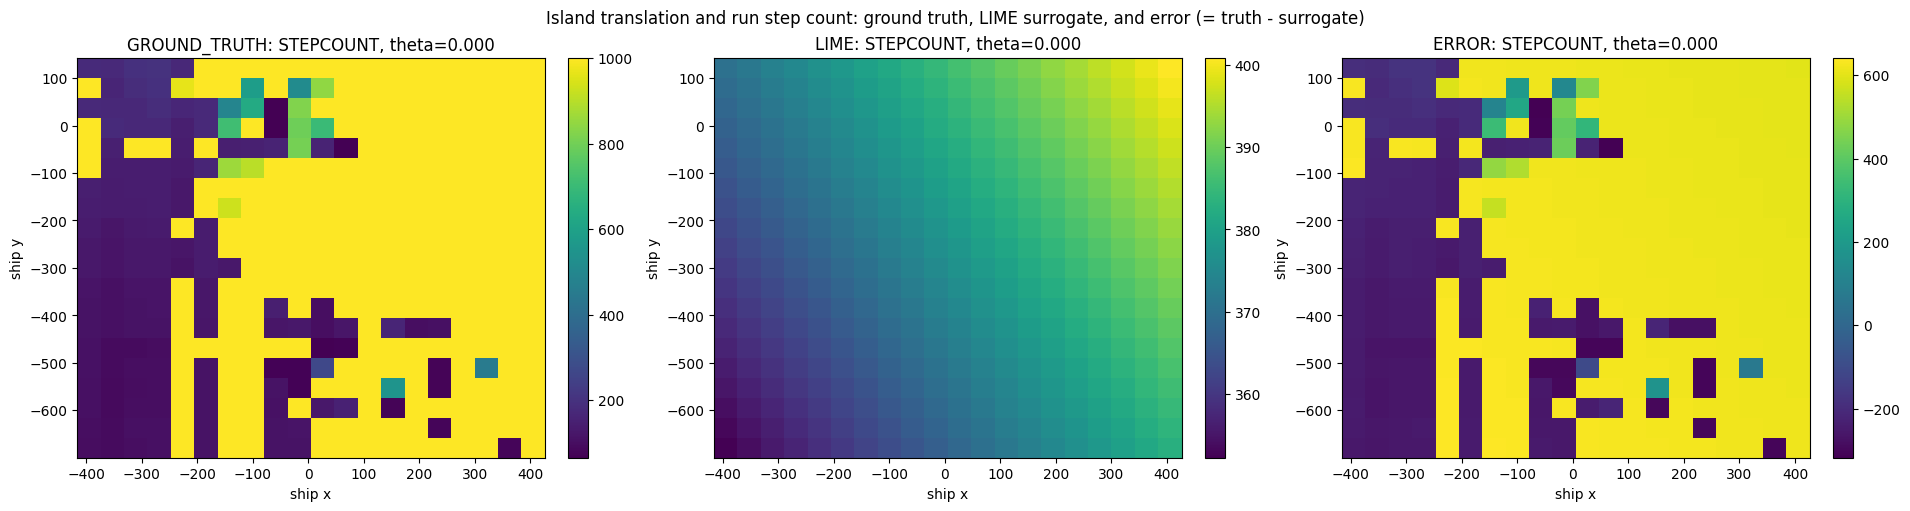

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)
island
lime.plot_grid(
    island_grid_field, RunValueClass.STEPCOUNT,
    source=Source.GROUND_TRUTH, theta_index=0, ax=axes[0],
    x_label = "ship x", y_label = "ship y",
)
lime.plot_grid(
    island_grid_field, RunValueClass.STEPCOUNT,
    source=Source.LIME, theta_index=0, ax=axes[1],
    x_label = "ship x", y_label = "ship y",
)
lime.plot_grid(
    island_grid_field, RunValueClass.STEPCOUNT,
    source=Source.ERROR, theta_index=0, ax=axes[2],
    x_label = "ship x", y_label = "ship y",
)

fig.suptitle("Island translation and run step count: ground truth, LIME surrogate, and error (= truth - surrogate)")
plt.show()